# Simpson's Paradox in Linear Regression

A small simulation showing how the sign of a regression coefficient can flip depending on whether a correlated variable is controlled for.

**Data-generating process** (synthetic, N = 2,000):

- `X` (building age): mixture of two clusters around 1 and 2
- `W` (complex size): strongly correlated with `X`
- `Y` (price per pyeong): `Y = 3 - 1·X + 2·W + ε`

Holding `W` fixed, older buildings are cheaper (slope −1). But because older buildings also tend to sit in larger complexes, a simple regression of `Y` on `X` alone finds a **positive** slope.

## 1. Multiple regression: Y ~ X + W

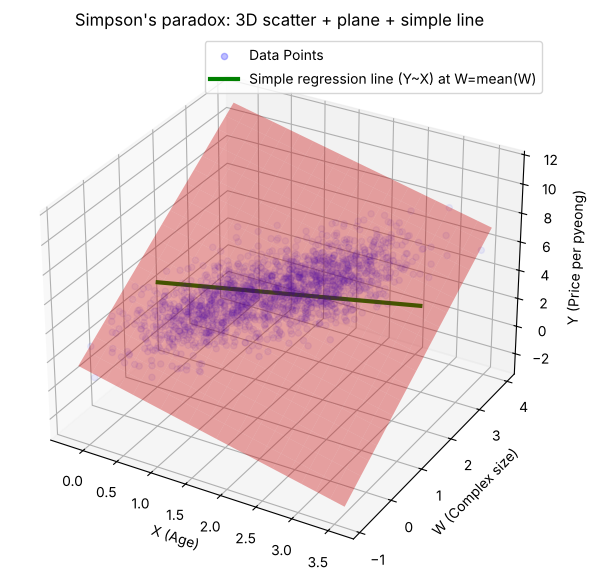

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LinearRegression


np.random.seed(42)
N = 2000

# X (Age): 50/50 mixture around 1 and 2, plus N(0, 0.4)
x_center = np.where(np.random.rand(N) < 0.5, 1, 2)
x = (x_center + np.random.normal(0, 0.4, N)).reshape(-1, 1)

# W (Complex size): strongly positively related to X
w = (x.reshape(-1) + np.random.normal(0, 0.4, N)).reshape(-1, 1)

# e ~ N(0, 0.4)
e = np.random.normal(0, 0.4, N).reshape(-1, 1)

# True DGP: Y = 3 - 1X + 2W + e
y = 3 - 1 * x + 2 * w + e


# Multiple regression: Y ~ X + W
X = np.hstack((x, w))
reg = LinearRegression().fit(X, y)
y_pred = reg.predict(X)


# Regression plane
x_range = np.linspace(x.min(), x.max(), 20)
w_range = np.linspace(w.min(), w.max(), 20)
X_plane, W_plane = np.meshgrid(x_range, w_range)
Y_plane = (
    reg.intercept_
    + reg.coef_[0, 0] * X_plane
    + reg.coef_[0, 1] * W_plane
)

# Simple regression (for a 3D line): Y ~ X
reg_x_for_3d = LinearRegression().fit(x, y)
x_line = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
y_line = reg_x_for_3d.predict(x_line)
w_bar = np.full_like(x_line, w.mean())


# Plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x, w, y, color='blue', alpha=0.25, label="Data Points")
ax.plot_surface(X_plane, W_plane, Y_plane, color='red', alpha=0.35)

ax.plot(
    x_line,
    w_bar,
    y_line,
    color="green",
    linewidth=3,
    label="Simple regression line (Y~X) at W=mean(W)",
)

ax.set_xlabel("X (Age)")
ax.set_ylabel("W (Complex size)")
ax.set_zlabel("Y (Price per pyeong)")
ax.set_title("Simpson's paradox: 3D scatter + plane + simple line")
ax.legend()

plt.show()


In [2]:

intercept = reg.intercept_[0]
coef_x = reg.coef_[0, 0]
coef_w = reg.coef_[0, 1]


regression_equation = f"y = {intercept:.2f} + ({coef_x:.2f} * x) + ({coef_w:.2f} * w)"
regression_equation


'y = 3.00 + (-1.05 * x) + (2.04 * w)'

## 2. Simple regression: Y ~ X

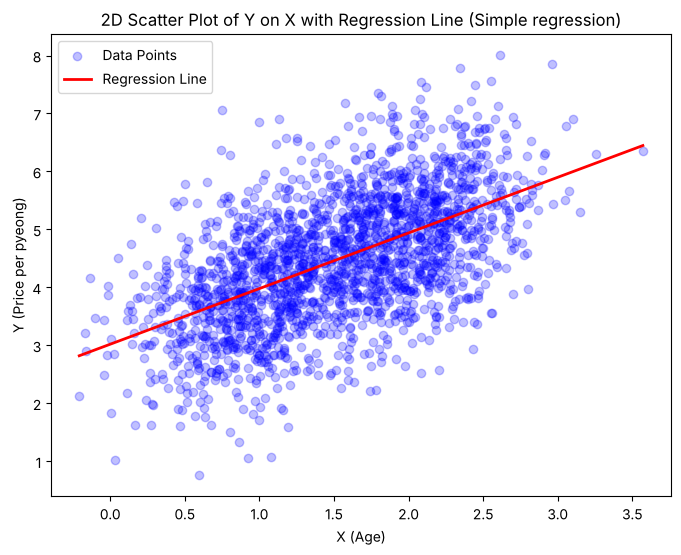

In [3]:
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', alpha=0.25, label="Data Points")

reg_x = LinearRegression().fit(x, y)
y_x_pred = reg_x.predict(x)

# sort for a clean line
idx = np.argsort(x[:, 0])
plt.plot(x[idx], y_x_pred[idx], color='red', linewidth=2, label="Regression Line")

plt.xlabel("X (Age)")
plt.ylabel("Y (Price per pyeong)")
plt.title("2D Scatter Plot of Y on X with Regression Line (Simple regression)")
plt.legend()
plt.show()


In [4]:

intercept_x = reg_x.intercept_[0]
coef_x_only = reg_x.coef_[0, 0]


regression_equation_x = f"y = {intercept_x:.2f} + ({coef_x_only:.2f} * x)"
regression_equation_x


'y = 3.02 + (0.96 * x)'

## 3. Projecting the 3D scatter onto 2D

- onto the (X, Y) plane
- onto the (W, Y) plane

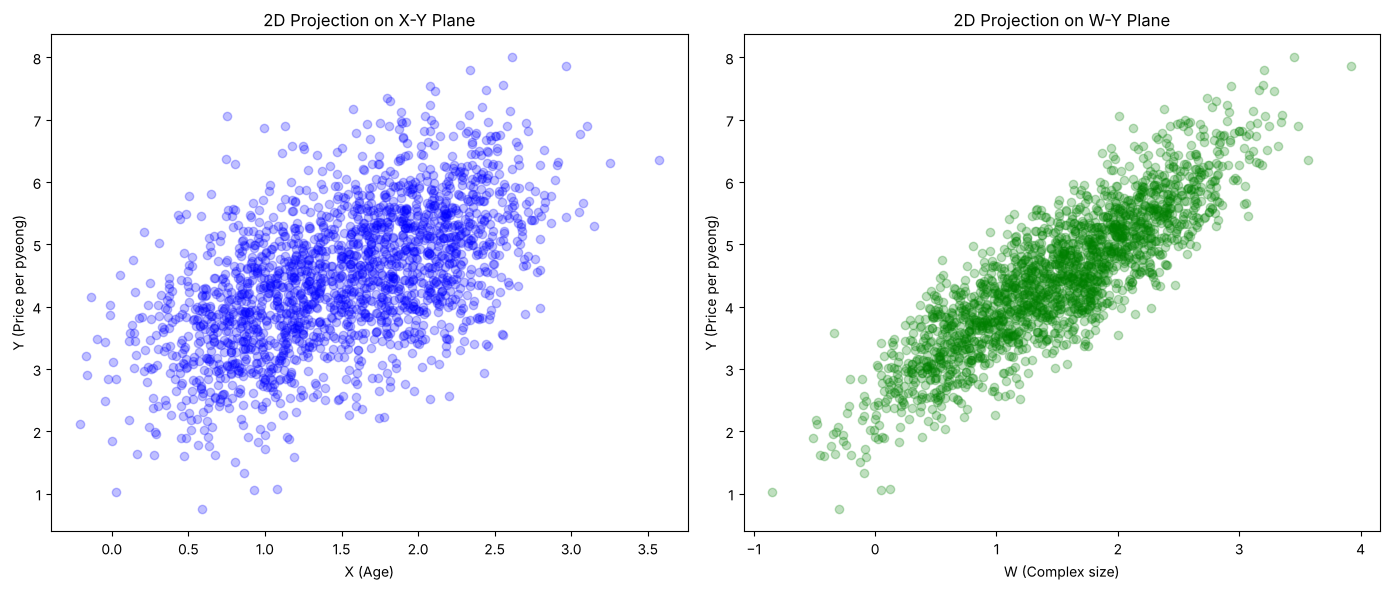

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

axs[0].scatter(x, y, color='blue', alpha=0.25, label="Projection on X-Y")
axs[0].set_xlabel("X (Age)")
axs[0].set_ylabel("Y (Price per pyeong)")
axs[0].set_title("2D Projection on X-Y Plane")

axs[1].scatter(w, y, color='green', alpha=0.25, label="Projection on W-Y")
axs[1].set_xlabel("W (Complex size)")
axs[1].set_ylabel("Y (Price per pyeong)")
axs[1].set_title("2D Projection on W-Y Plane")

plt.tight_layout()
plt.show()


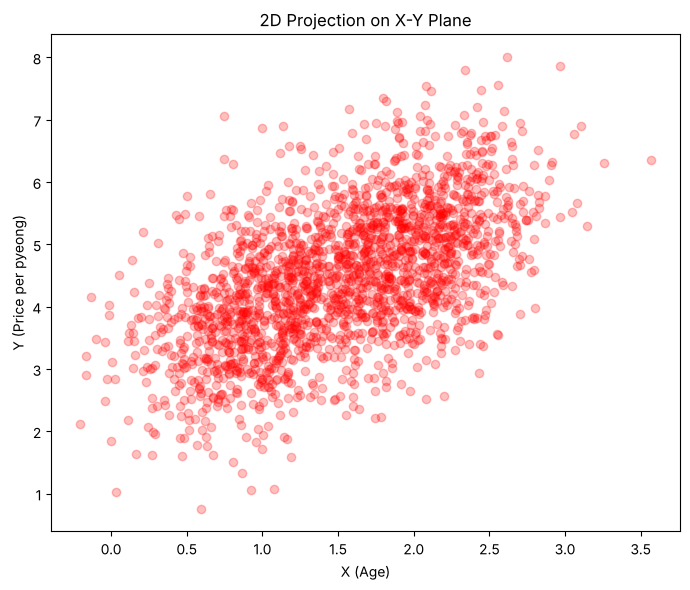

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(x, y, color='red', alpha=0.25)
ax.set_xlabel("X (Age)")
ax.set_ylabel("Y (Price per pyeong)")
ax.set_title("2D Projection on X-Y Plane")

plt.tight_layout()
plt.show()


## 4. Adding the simple regression lines

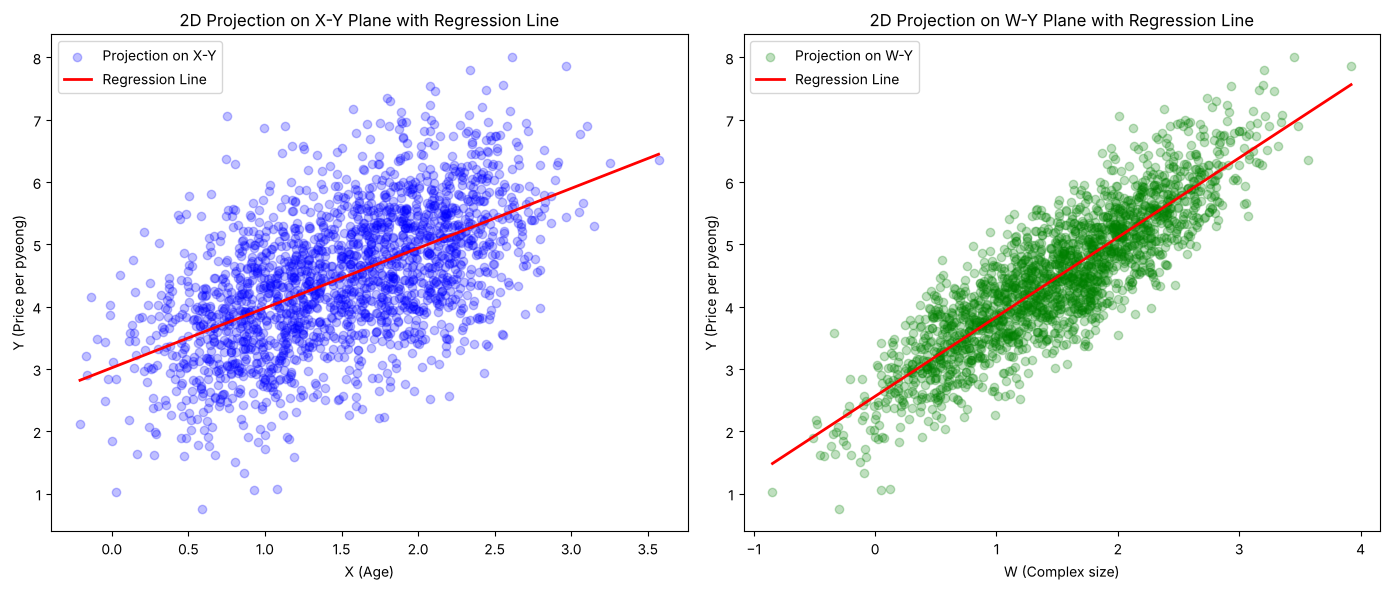

In [7]:
import pandas as pd

reg_x = LinearRegression().fit(x, y)
y_x_pred = reg_x.predict(x)

reg_w = LinearRegression().fit(w, y)
y_w_pred = reg_w.predict(w)

fig, axs = plt.subplots(1, 2, figsize=(14, 6))

# X-Y with regression line
axs[0].scatter(x, y, color='blue', alpha=0.25, label="Projection on X-Y")
idx_x = np.argsort(x[:, 0])
axs[0].plot(x[idx_x], y_x_pred[idx_x], color='red', linewidth=2, label="Regression Line")
axs[0].set_xlabel("X (Age)")
axs[0].set_ylabel("Y (Price per pyeong)")
axs[0].set_title("2D Projection on X-Y Plane with Regression Line")
axs[0].legend()

# W-Y with regression line
axs[1].scatter(w, y, color='green', alpha=0.25, label="Projection on W-Y")
idx_w = np.argsort(w[:, 0])
axs[1].plot(w[idx_w], y_w_pred[idx_w], color='red', linewidth=2, label="Regression Line")
axs[1].set_xlabel("W (Complex size)")
axs[1].set_ylabel("Y (Price per pyeong)")
axs[1].set_title("2D Projection on W-Y Plane with Regression Line")
axs[1].legend()

plt.tight_layout()
plt.show()


## 5. Why the sign flips: total vs. partial slope

The simple-regression slope equals the partial slope of `X` plus the indirect path through `W`:

$$\frac{dY}{dX}\Big|_{\text{total}} = b_X + b_W \cdot \frac{dW}{dX}$$

In [8]:
# Flatten (in case x,w are column vectors)
xv = x.reshape(-1)
wv = w.reshape(-1)

# Slopes on the fitted regression plane: m_hat(x,w) = a + bX*x + bW*w
bX = float(reg.coef_[0, 0])   # partial slope wrt X (hold W fixed)
bW = float(reg.coef_[0, 1])   # partial slope wrt W (hold X fixed)

# "Path" slope: how W moves with X in THIS dataset (best linear approximation)
# w_hat(x) = alpha + gamma*x  -> gamma ≈ dW/dX
Xmat = np.c_[np.ones_like(xv), xv]
alpha, gamma = np.linalg.lstsq(Xmat, wv, rcond=None)[0]

# Total vs partial decomposition
direct   = bX
indirect = bW * gamma
total_pred = direct + indirect

simple = float(reg_x.coef_[0, 0])  # slope from simple regression Y~X

decomp = pd.DataFrame(
    {"slope": [direct, indirect, total_pred, simple]},
    index=[
        "partial (hold W fixed):          bX",
        "indirect (W moves with X):       bW * (dW/dX)",
        "total along the path:            bX + bW*(dW/dX)",
        "simple regression slope (Y~X):   ",
    ],
).round(3)

decomp


,slope
partial (hold W fixed): bX,-1.051
indirect (W moves with X): bW * (dW/dX),2.011
total along the path: bX + bW*(dW/dX),0.960
simple regression slope (Y~X):,0.960


In [9]:
# Recompute only what we need (keeps this block self-contained & robust)
bX = float(reg.coef_[0, 0])          # partial slope wrt X on the plane
bW = float(reg.coef_[0, 1])          # partial slope wrt W on the plane
simple = float(reg_x.coef_[0, 0])    # slope from simple regression Y~X

xv = x.reshape(-1)
wv = w.reshape(-1)

# gamma ≈ dW/dX : best linear approximation of how W moves with X in the data
gamma = np.mean((xv - xv.mean()) * (wv - wv.mean())) / np.mean((xv - xv.mean())**2)

direct = bX
indirect = bW * gamma
total = direct + indirect

gamma_star = -direct / bW  # threshold where total becomes positive (if bW>0)

print("TOTAL vs PARTIAL (clean)")
print(f"  Partial (hold W fixed):        bX = {direct:+.3f}")
print(f"  Path term (W moves with X):     bW*(dW/dX) = ({bW:+.3f})*({gamma:.3f}) = {indirect:+.3f}")
print(f"  Total along the path:           bX + bW*(dW/dX) = {total:+.3f}")
print(f"  Simple regression slope (Y~X):  {simple:+.3f}")




TOTAL vs PARTIAL (clean)
  Partial (hold W fixed):        bX = -1.051
  Path term (W moves with X):     bW*(dW/dX) = (+2.044)*(0.983) = +2.011
  Total along the path:           bX + bW*(dW/dX) = +0.960
  Simple regression slope (Y~X):  +0.960


## 6. Animation

Rotating the 3D view until it lines up with the (X, Y) plane: the negative-slope plane, seen edge-on, turns into the positive simple-regression line.

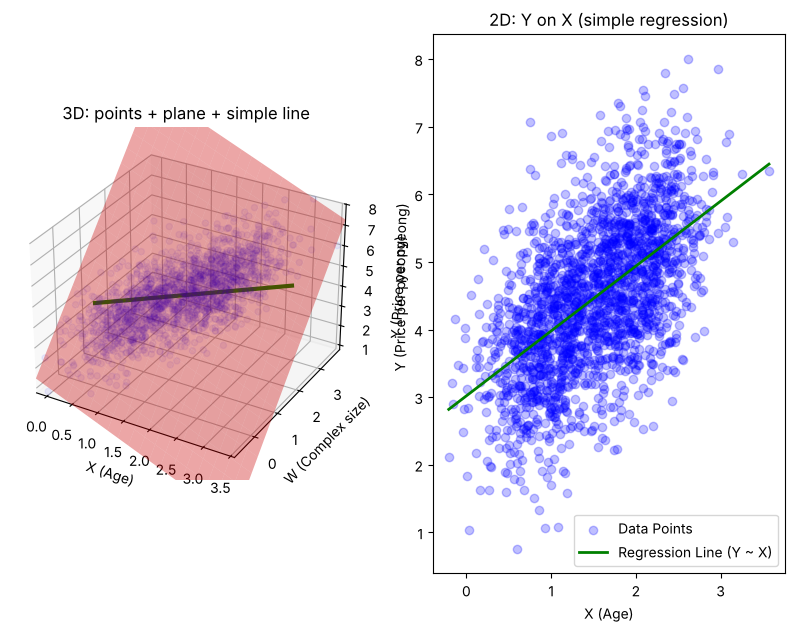

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LinearRegression


np.random.seed(42)
N = 2000

# X (Age): mixture around 1 and 2
x_center = np.where(np.random.rand(N) < 0.5, 1, 2)
x = (x_center + np.random.normal(0, 0.4, N)).reshape(-1, 1)

# W (Complex size): strongly positively related to X
w = (x.reshape(-1) + np.random.normal(0, 0.4, N)).reshape(-1, 1)

# e ~ N(0, 0.4)
e = np.random.normal(0, 0.4, N).reshape(-1, 1)

# True DGP
y = 3 - 1 * x + 2 * w + e


# Multiple regression: Y ~ X + W (plane)
multi_reg = LinearRegression().fit(np.hstack((x, w)), y)

x_range = np.linspace(x.min(), x.max(), 20)
w_range = np.linspace(w.min(), w.max(), 20)
X_plane, W_plane = np.meshgrid(x_range, w_range)
Y_plane = (
    multi_reg.intercept_
    + multi_reg.coef_[0, 0] * X_plane
    + multi_reg.coef_[0, 1] * W_plane
)

# Simple regression: Y ~ X (line)
simple_reg = LinearRegression().fit(x, y)
x_line = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
y_line = simple_reg.predict(x_line)
w_bar = np.full_like(x_line, w.mean())


fig = plt.figure(figsize=(10, 7))
ax3d = fig.add_subplot(121, projection='3d')
ax2d = fig.add_subplot(122)

# 3D: points + plane + simple line
ax3d.scatter(x, w, y, color='blue', alpha=0.25, label="Data Points")
ax3d.plot_surface(X_plane, W_plane, Y_plane, color='red', alpha=0.35)
ax3d.plot(x_line, w_bar, y_line, color="green", linewidth=3, label="Simple regression line (Y~X)")

ax3d.set_xlabel("X (Age)")
ax3d.set_ylabel("W (Complex size)")
ax3d.set_zlabel("Y (Price per pyeong)")
ax3d.set_title("3D: points + plane + simple line")
ax3d.set_xlim(x.min(), x.max())
ax3d.set_ylim(w.min(), w.max())
ax3d.set_zlim(y.min(), y.max())

# 2D: Y on X with regression line
ax2d.scatter(x, y, color='blue', alpha=0.25, label="Data Points")
y_x_pred = simple_reg.predict(x)
idx = np.argsort(x[:, 0])
ax2d.plot(x[idx], y_x_pred[idx], color='green', linewidth=2, label="Regression Line (Y ~ X)")
ax2d.set_xlabel("X (Age)")
ax2d.set_ylabel("Y (Price per pyeong)")
ax2d.set_title("2D: Y on X (simple regression)")
ax2d.legend()

def update_projection(frame):
    angle = -30 - 3 * frame
    ax3d.view_init(elev=6, azim=angle)

ani = animation.FuncAnimation(fig, update_projection, frames=60, interval=100)

plt.show()


In [11]:
from matplotlib.animation import PillowWriter

ani.save("assets/simpsons_paradox_rotation.gif", writer=PillowWriter(fps=10))